# Clustering analysis

Alex Koiter

## Load libraries

In [ ]:
suppressPackageStartupMessages({
  library(tidyverse)
  library(terra)
  library(patchwork)
  library(sf)
  library(randomForest)
  library(tidyterra)
  library(gt)
})

## Load data

In [ ]:
ag_data <- read_csv(here::here("./notebooks/ag_terrain_data.csv"), show_col_types = FALSE) 


forest_data <- read_csv(here::here("./notebooks/forest_terrain_data.csv"), show_col_types = FALSE) 

## Elbow plot functions

In [ ]:
# Define function to compute WSS for a single cluster
wss <- function(d) {
  sum(scale(d, scale = FALSE)^2)
}

# Wrapper function to apply WSS calculation across clusters for a given k
wrap <- function(i, hc, x) {
  cl <- cutree(hc, i)  # Cut tree into i clusters
  spl <- split(x, cl)  # Split data by cluster membership
  total_wss <- sum(sapply(spl, wss))  # Sum WSS across all clusters
  total_wss
}

## Terrain Atributes

In [ ]:
attributes <- c("saga_wetness_index", "relative_slope_position", "elevation", "profile_curvature", "plan_curvature","channel_network_distance","catchment_area")

## Agricultural site

In [ ]:
set.seed(123)
# Principle component
ag_pc <- prcomp(dplyr::select(ag_data, all_of(attributes)), center = TRUE, scale. = TRUE)$x |> 
  as.data.frame()

# Unsuperivsied classification

rf_ag_fit <- randomForest(x = dplyr::select(ag_data, any_of(attributes)), y = NULL, ntree = 500, importance = TRUE)

# Cluster analysis
hclust_ag_rf <- hclust(as.dist(1-rf_ag_fit$proximity), method = "ward.D2")

# #plot(hclust_ag_rf)

### Elbow plot

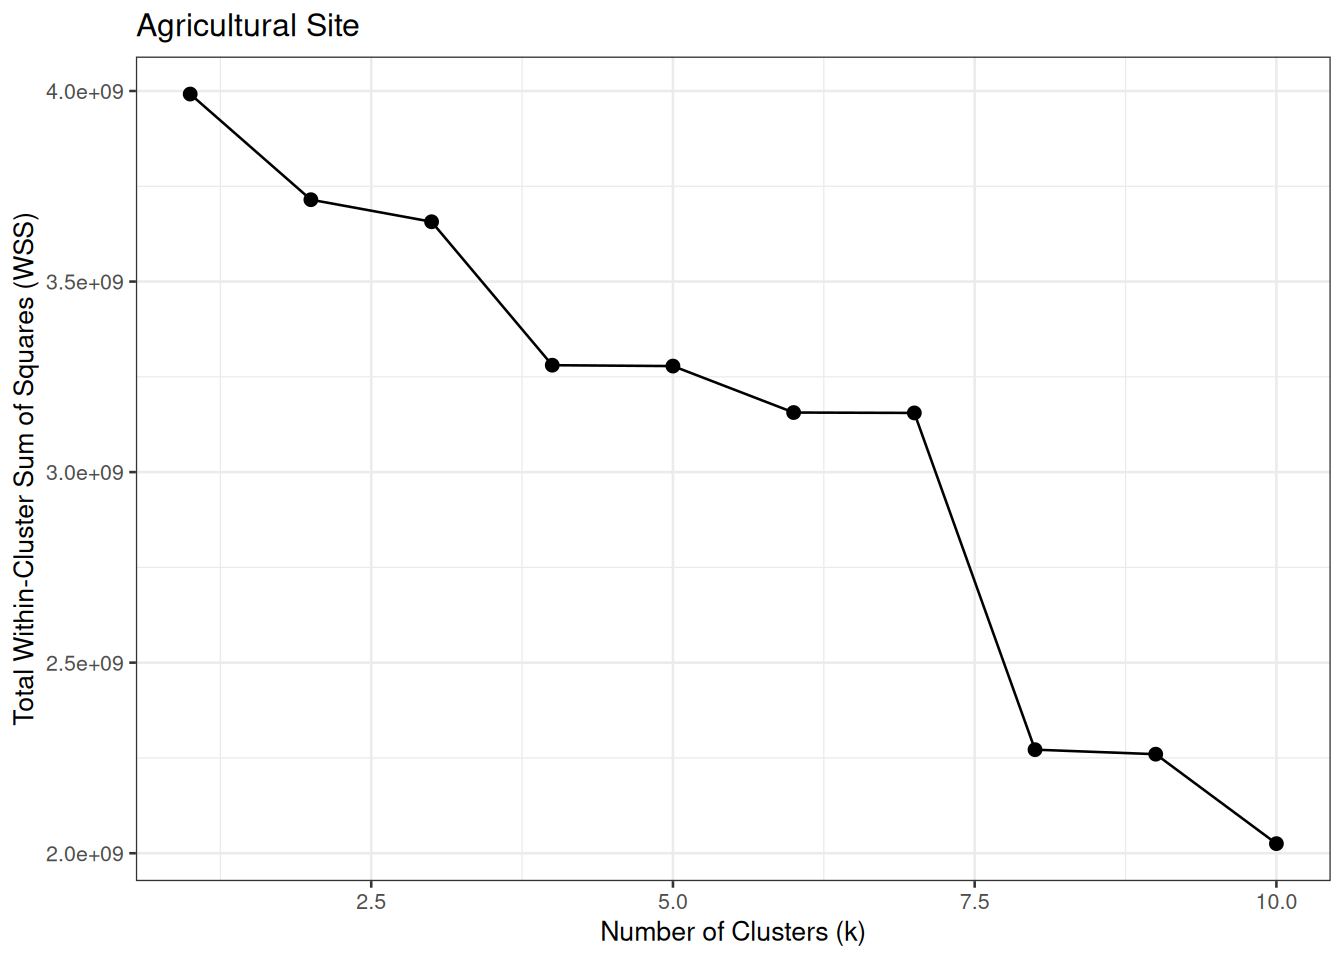

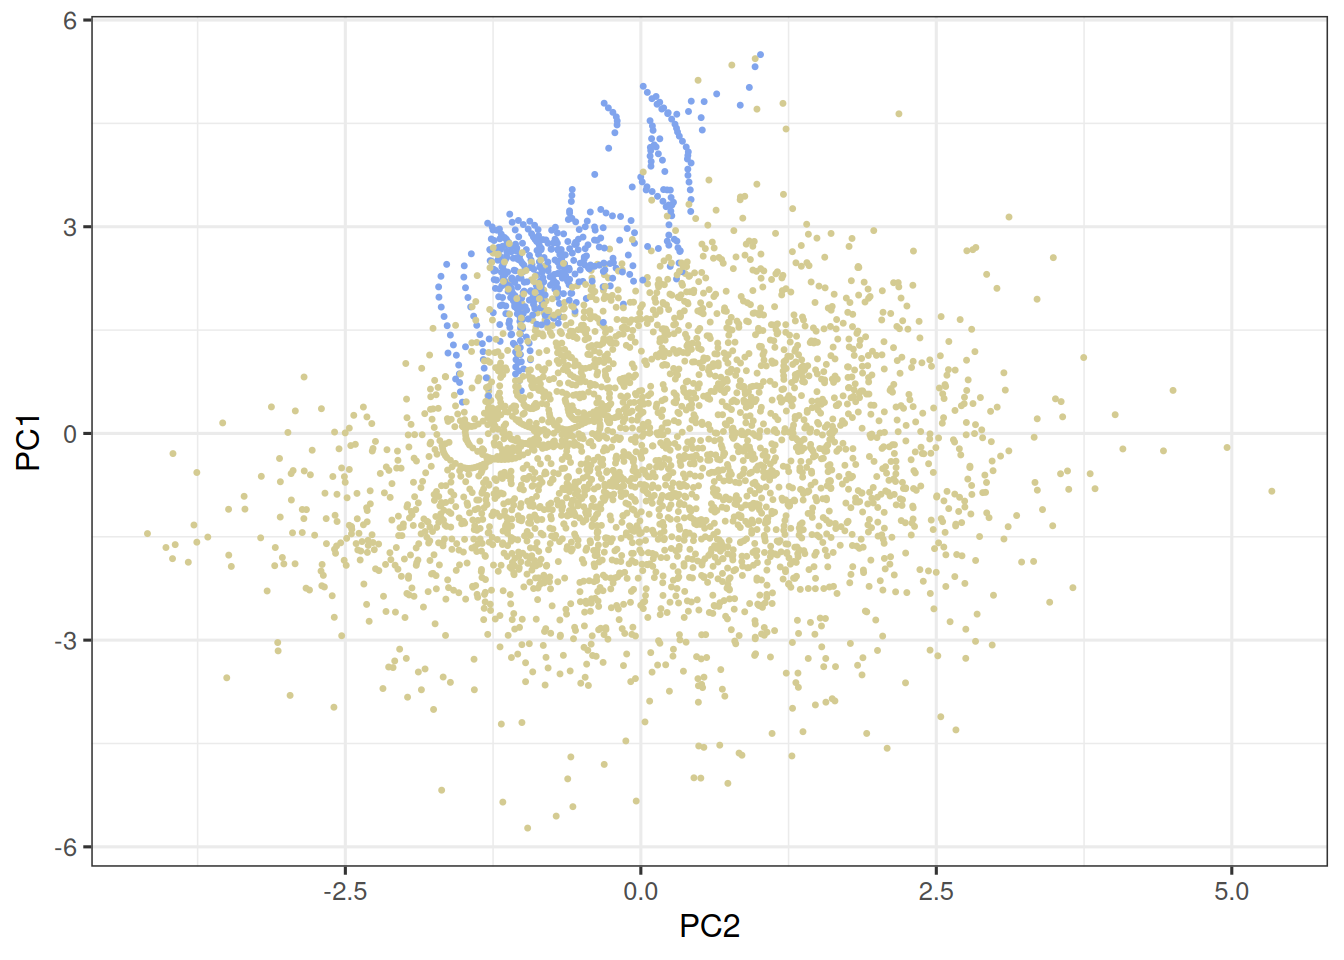

In [ ]:
# Compute WSS for k = 1 to 10
k_values <- 1:10
wss_values <- sapply(k_values, wrap, hc = hclust_ag_rf, x = dplyr::select(ag_data, any_of(attributes)))

# Plot the elbow plot
k_plot_ag <- ggplot(data.frame(k = k_values, wss = wss_values), aes(x = k, y = wss)) +
  geom_line() +
  geom_point(shape = 19, size = 2) +
  labs(
    x = "Number of Clusters (k)",
    y = "Total Within-Cluster Sum of Squares (WSS)",
    title = "Agricultural Site"
  ) +
  theme_bw(base_size = 10)
k_plot_ag

Warning in cmdscale(ag_dist, k = nrow(ag_data) - 1, eig = TRUE): only 2455 of
the first 3905 eigenvalues are > 0

[1] 0.0616989

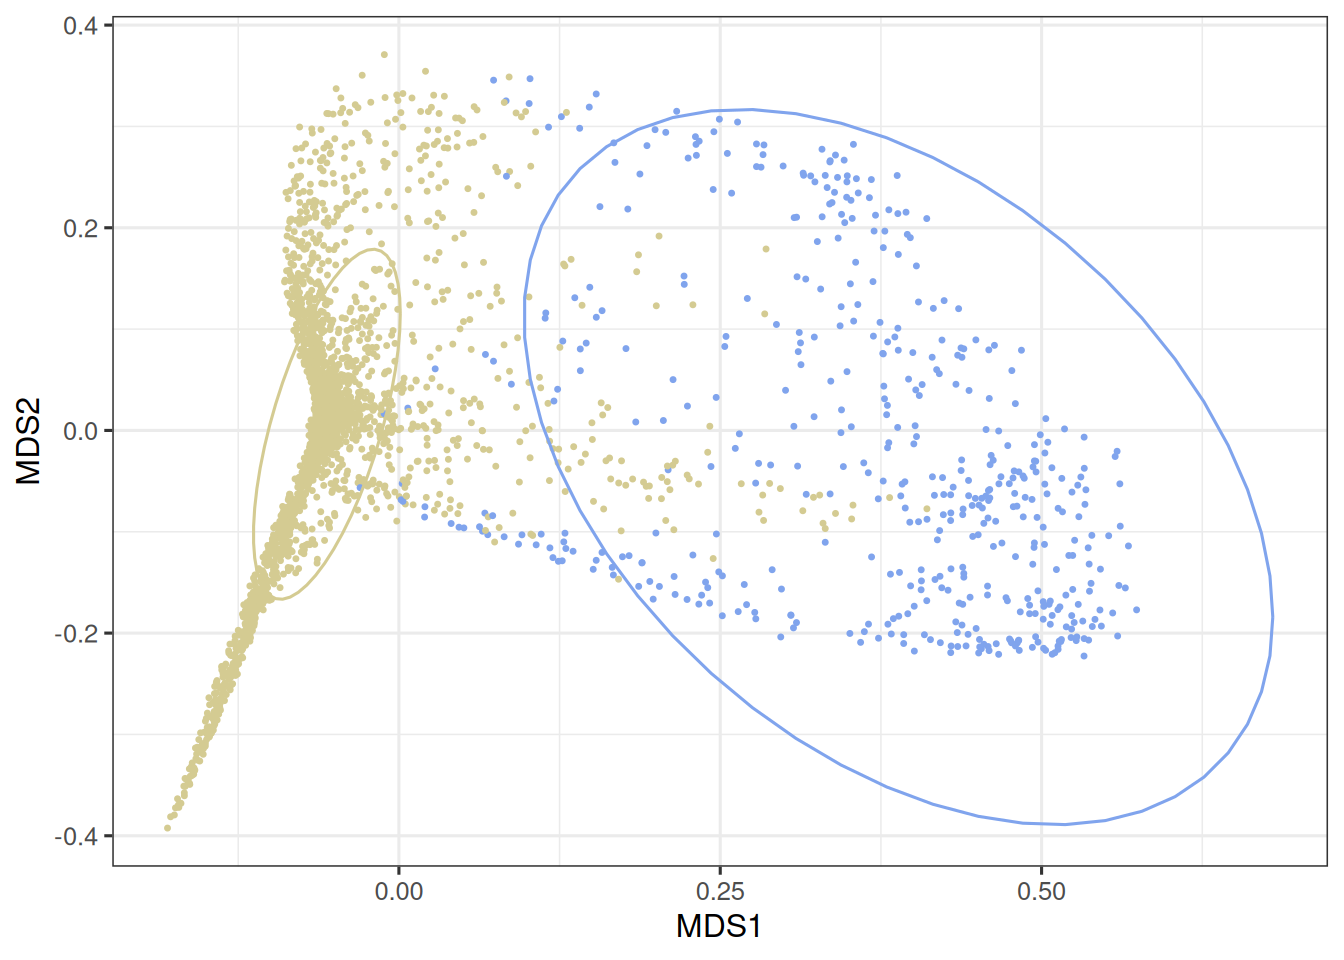

In [ ]:
ag_dist <- as.dist(1 - rf_ag_fit$proximity)
ag_mds <- cmdscale(ag_dist, k = nrow(ag_data) - 1, eig = TRUE)

In [ ]:
ag_cluster_summary <- ag_data |>
  dplyr::select(all_of(attributes)) |>
  dplyr::mutate(cluster = factor(cutree(hclust_ag_rf, k = 2))) |>
  dplyr::group_by(cluster) |>
  dplyr::summarise(dplyr::across(
    dplyr::everything(),
    list(mean = ~mean(.x, na.rm = TRUE),sd   = ~sd(.x,   na.rm = TRUE))
  ), .groups = "drop") |>
  tidyr::pivot_longer(cols = -cluster,
    names_to  = c("attribute", ".value"), 
    names_sep = "_(?=[^_]+$)"   ) |>
  dplyr::mutate(value = sprintf("%.1f (%.1f)", mean, sd)) |>
  dplyr::select(-mean, -sd) |>
  pivot_wider(names_from  = cluster,values_from = value )

ag_cluster_summary

# A tibble: 7 × 3
  attribute                `1`           `2`            
  <chr>                    <chr>         <chr>          
1 saga_wetness_index       9.5 (0.6)     10.6 (0.3)     
2 relative_slope_position  0.8 (0.2)     0.2 (0.2)      
3 elevation                310.0 (0.6)   309.2 (0.1)    
4 profile_curvature        -0.0 (0.0)    -0.0 (0.0)     
5 plan_curvature           0.0 (0.0)     -0.0 (0.0)     
6 channel_network_distance 0.1 (0.0)     0.0 (0.0)      
7 catchment_area           375.3 (728.4) 1183.9 (1983.2)

New names:
• `` -> `...3`

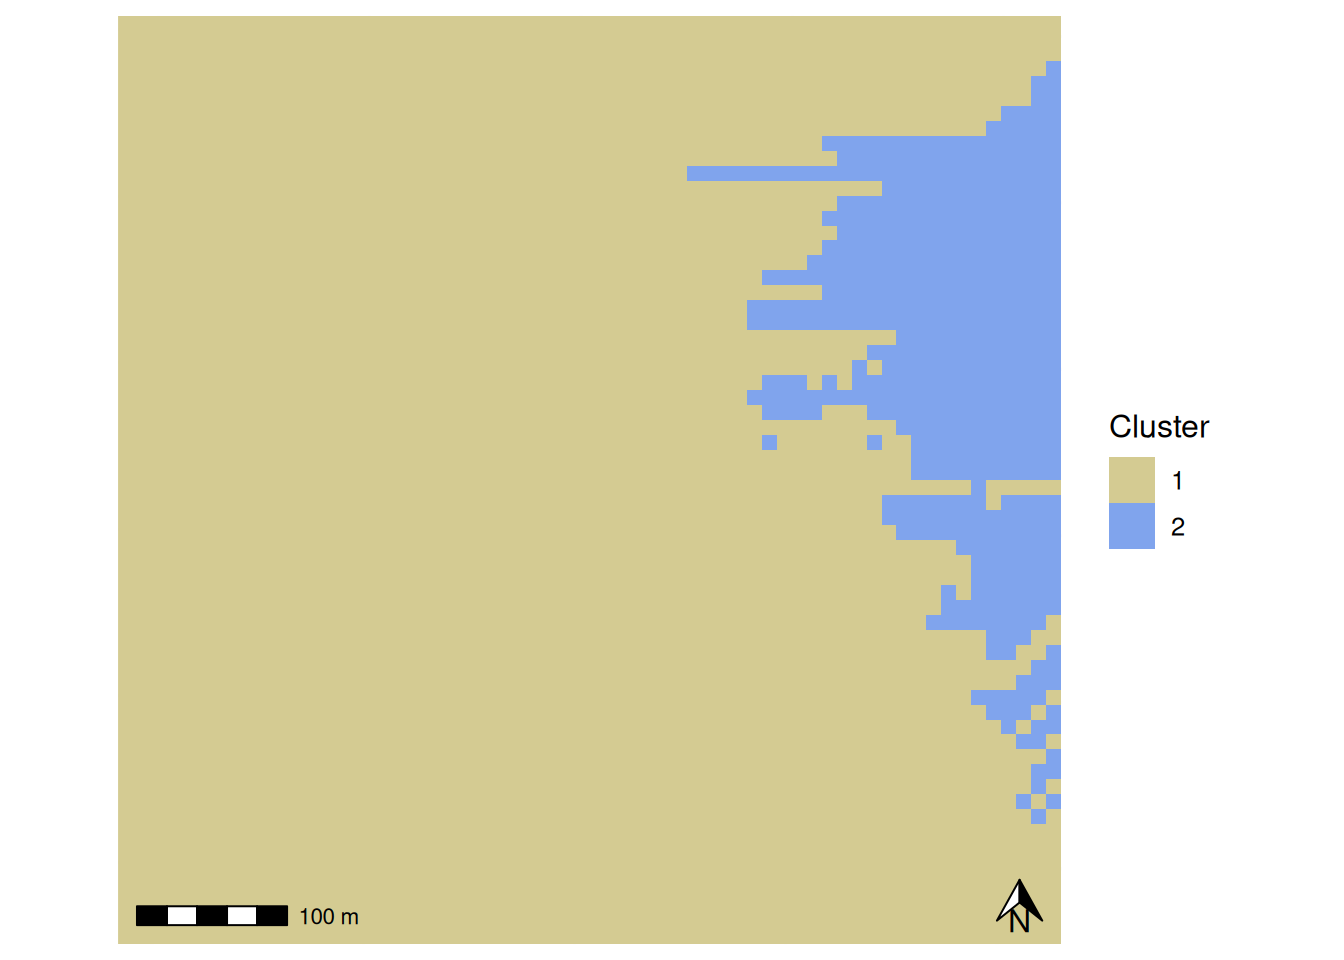

In [ ]:
cluster_map_ag <- ag_data |>
  dplyr::select(x, y) |>
  bind_cols(rf_cluster_ag) |>
  rename(cluster = ...3) |>
  rast()|>
  mutate(cluster = as.factor(cluster))

## forested site site

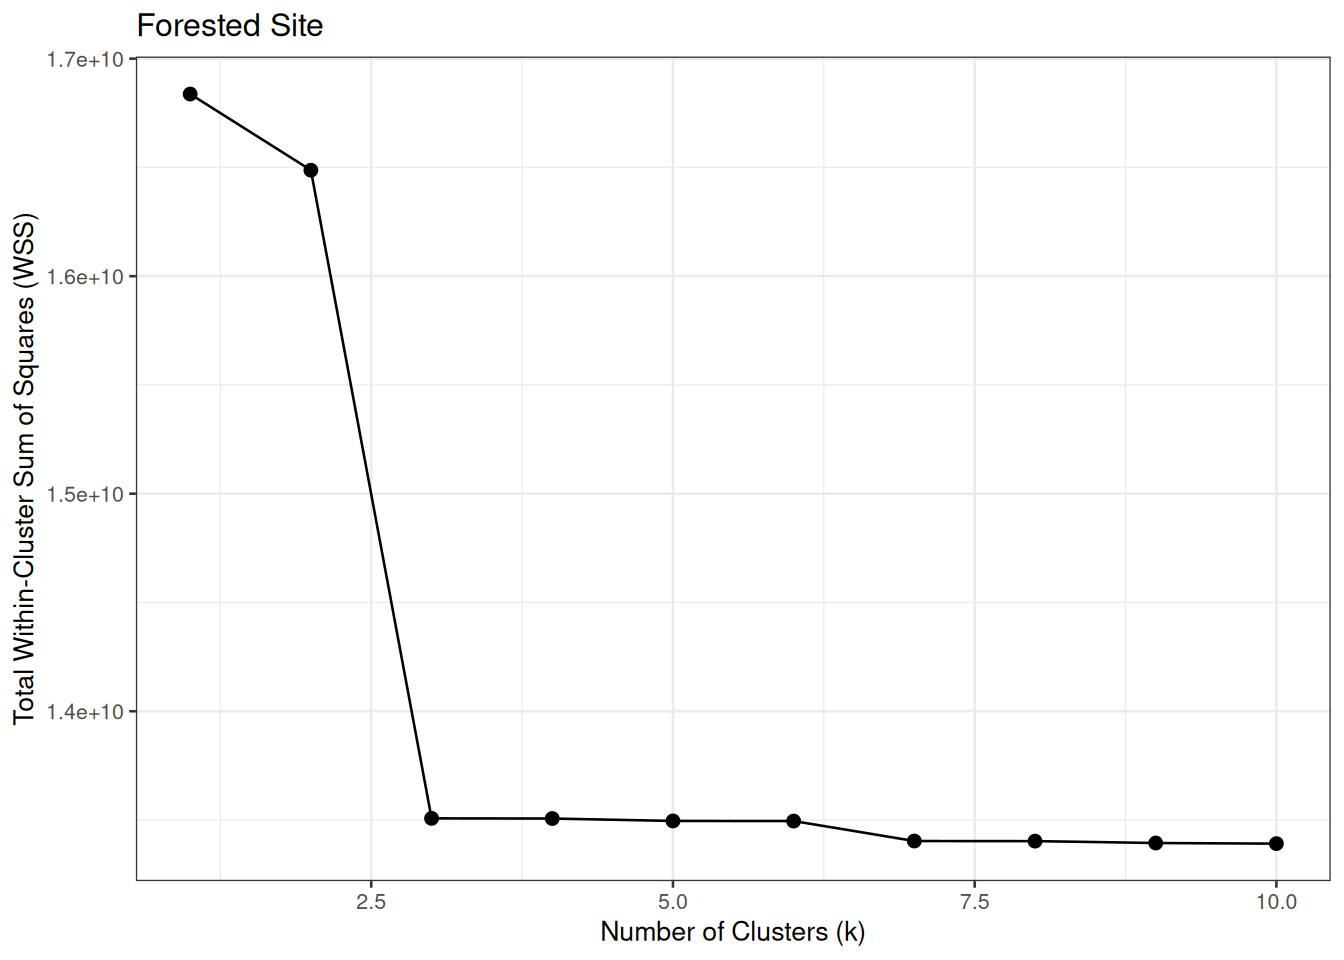

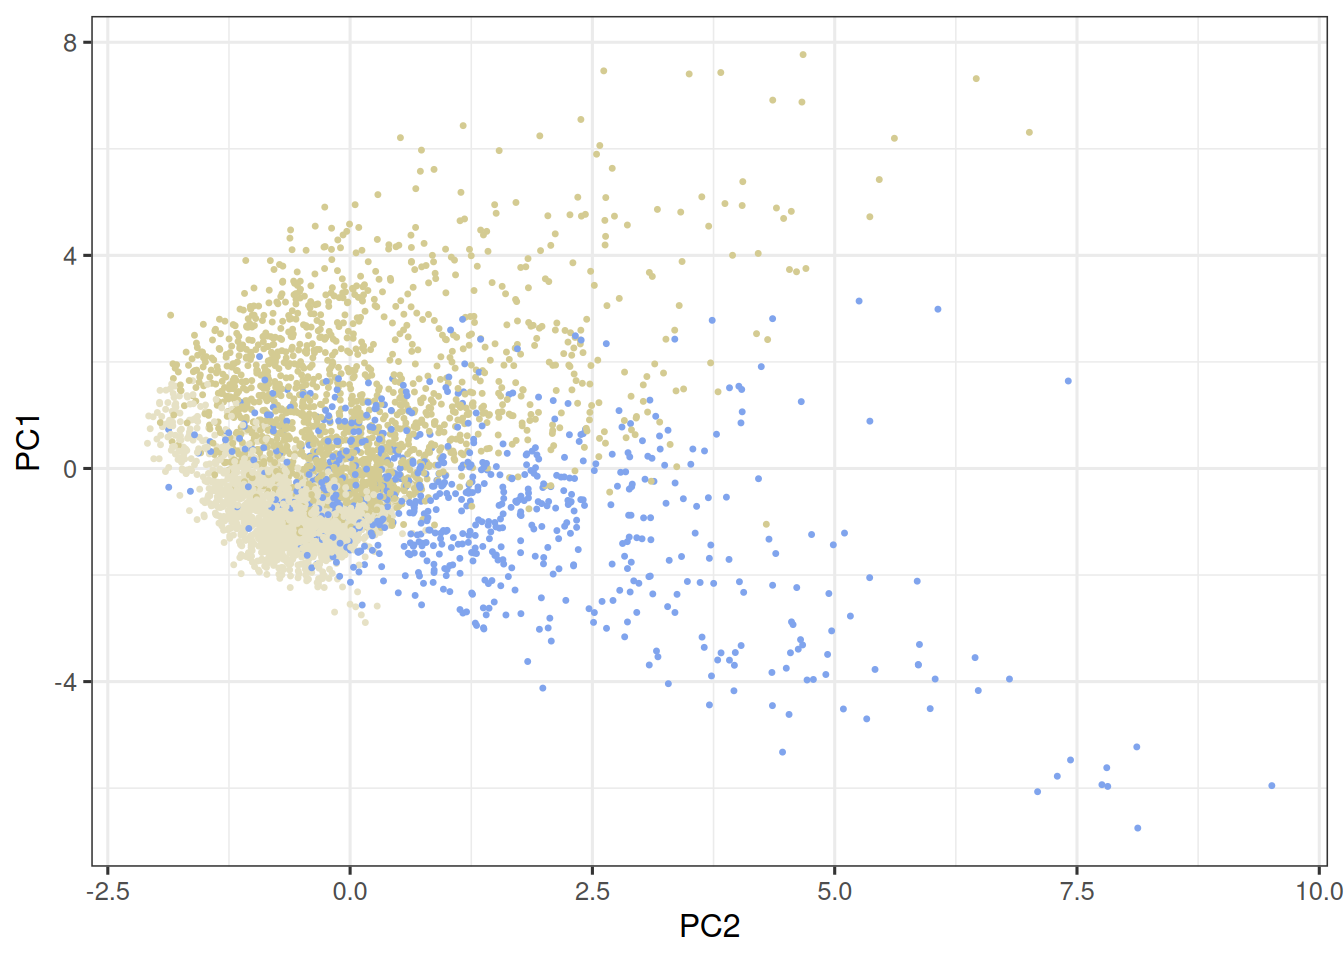

In [ ]:
forest_pc <- prcomp(dplyr::select(forest_data, all_of(attributes)), center = TRUE, scale. = TRUE)$x |> 
  as.data.frame()

set.seed(123)
rf_forest_fit <- randomForest(x = dplyr::select(forest_data, all_of(attributes)), y = NULL, ntree = 500, importance = TRUE)

hclust_forest_rf <- hclust(as.dist(1-rf_forest_fit$proximity), method = "average")


#plot(hclust_forest_rf)

# Compute WSS for k = 1 to 10
k_values <- 1:10
wss_values <- sapply(k_values, wrap, hc = hclust_forest_rf, x = dplyr::select(forest_data, plan_curvature:elevation))

# Plot the elbow plot

k_plot_forest <- ggplot(data.frame(k = k_values, wss = wss_values), aes(x = k, y = wss)) +
  geom_line() +
  geom_point(shape = 19, size = 2) +
  labs(
    x = "Number of Clusters (k)",
    y = "Total Within-Cluster Sum of Squares (WSS)",
    title = "Forested Site"
  ) +
  theme_bw(base_size = 10)
k_plot_forest

Warning in cmdscale(forest_dist, k = nrow(forest_data) - 1, eig = TRUE): only
2915 of the first 4484 eigenvalues are > 0

[1] 0.04702872

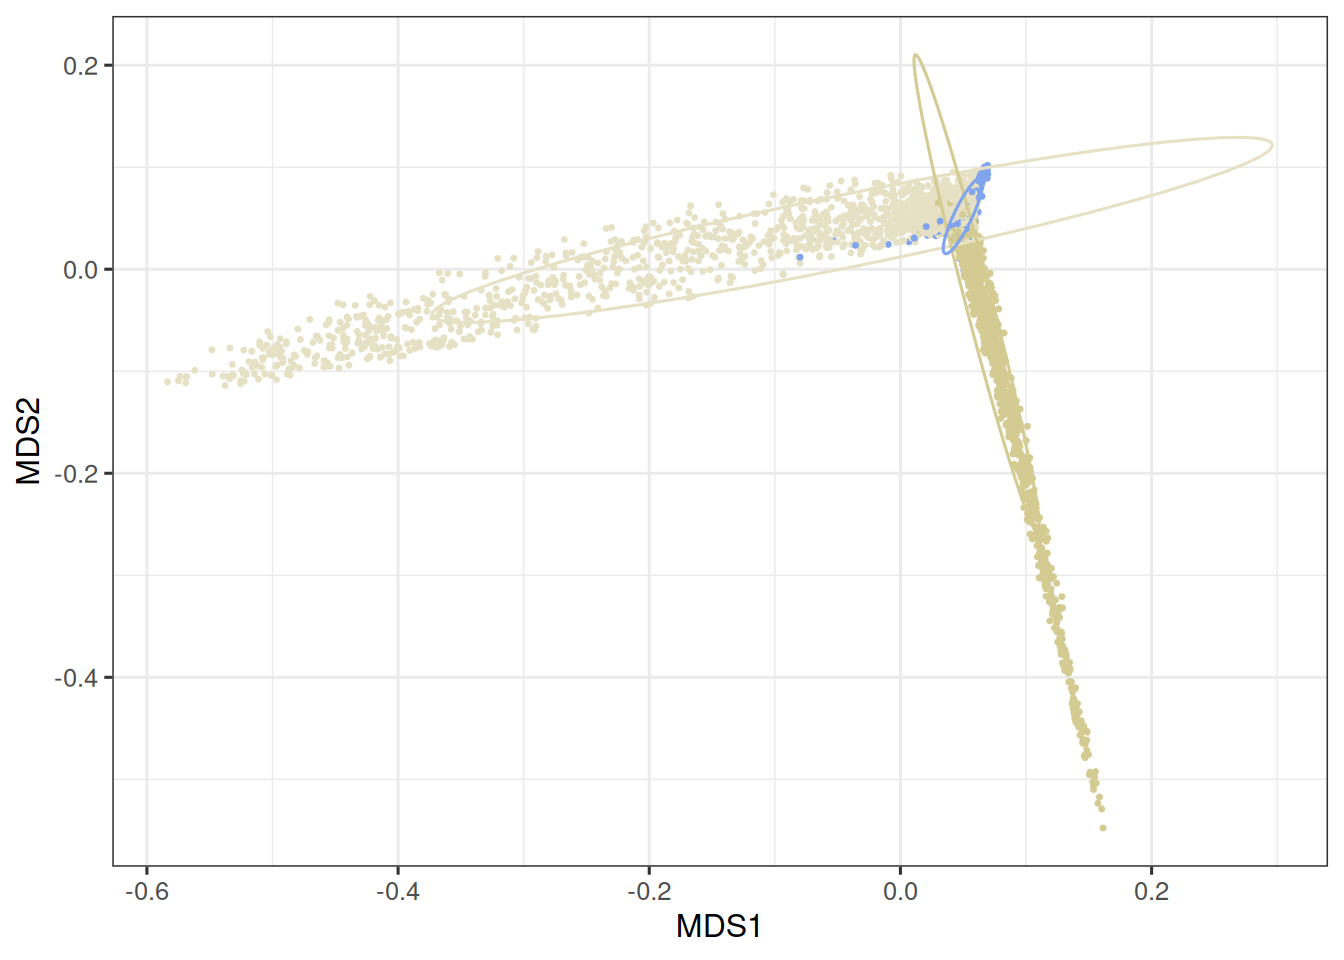

In [ ]:
forest_dist <- as.dist(1 - rf_forest_fit$proximity)
forest_mds <- cmdscale(forest_dist, k = nrow(forest_data) - 1, eig = TRUE)

In [ ]:
cluster_summary <- forest_data |>
  dplyr::select(all_of(attributes)) |>
  dplyr::mutate(cluster = factor(cutree(hclust_forest_rf, k = 3))) |>
  dplyr::group_by(cluster) |>
  dplyr::summarise(dplyr::across(
    dplyr::everything(),
    list(
      mean = ~mean(.x, na.rm = TRUE),
      sd   = ~sd(.x,   na.rm = TRUE)
    )
  ), .groups = "drop") |>
  tidyr::pivot_longer(
    cols      = -cluster,
    names_to  = c("attribute", ".value"),
    names_sep = "_(?=[^_]+$)"
  ) |>
  dplyr::mutate(
    value = sprintf("%.1f (%.1f)", mean, sd)
  ) |>
  dplyr::select(-mean, -sd) |>
  tidyr::pivot_wider(
    names_from  = cluster,
    values_from = value
  )

cluster_summary

# A tibble: 7 × 4
  attribute                `1`           `2`           `3`            
  <chr>                    <chr>         <chr>         <chr>          
1 saga_wetness_index       6.7 (0.6)     5.5 (0.9)     5.2 (0.9)      
2 relative_slope_position  0.1 (0.1)     0.4 (0.3)     0.1 (0.1)      
3 elevation                369.4 (2.5)   369.9 (3.3)   367.1 (4.4)    
4 profile_curvature        -0.0 (0.0)    0.0 (0.0)     -0.0 (0.0)     
5 plan_curvature           -0.0 (0.0)    0.0 (0.0)     0.0 (0.0)      
6 channel_network_distance 0.1 (0.1)     0.7 (0.5)     0.5 (0.3)      
7 catchment_area           252.3 (425.3) 147.1 (520.5) 2571.6 (4255.4)

New names:
• `` -> `...3`

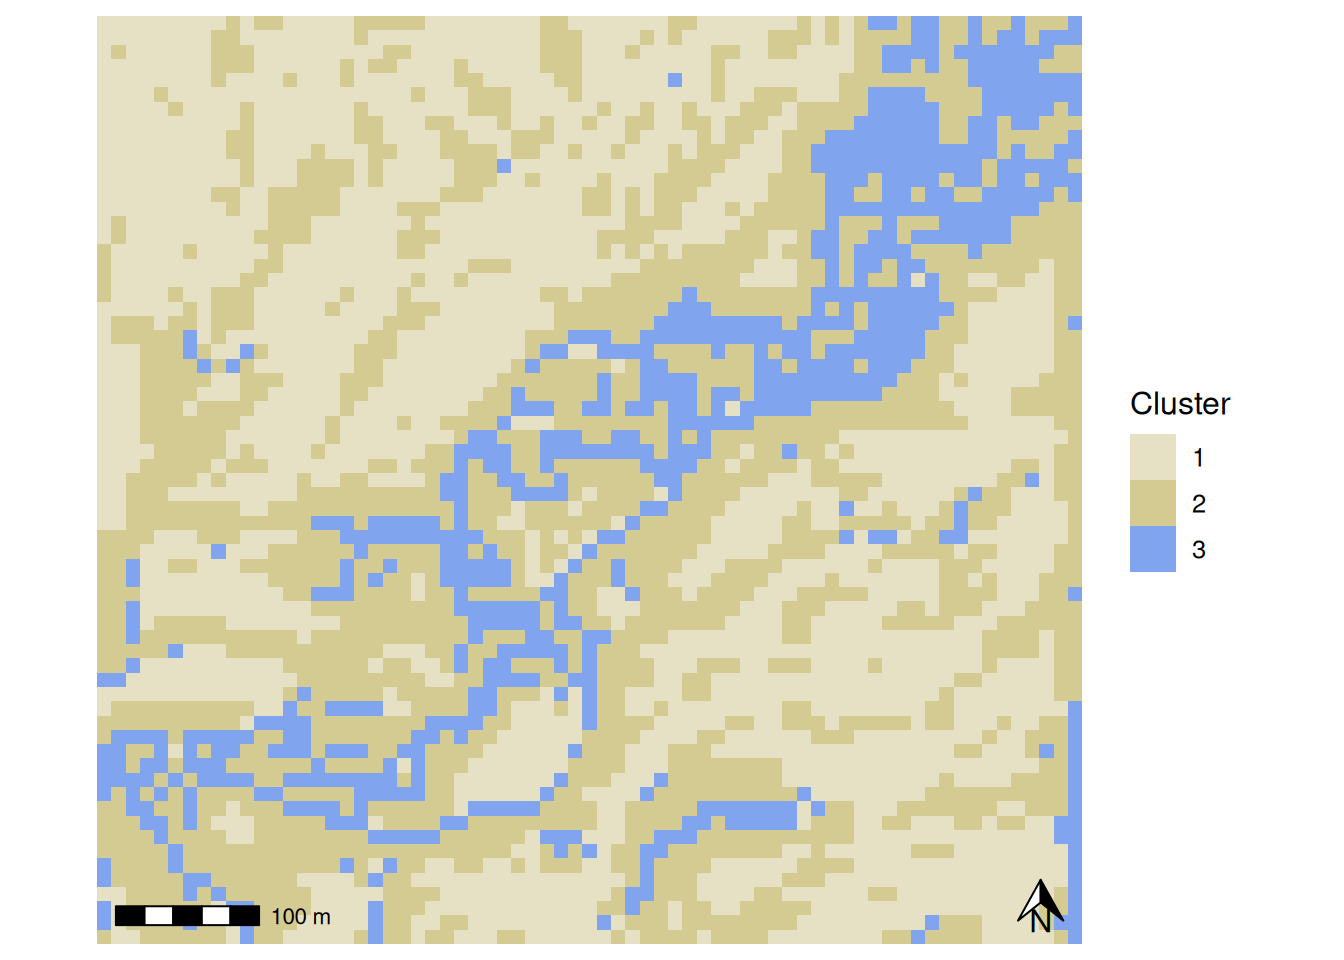

In [ ]:
cluster_map <- forest_data |>
  dplyr::select(x, y) |>
  bind_cols(rf_cluster_forest) |>
  rename(cluster = ...3) |>
  rast() |>
  mutate(cluster = as.factor(cluster))

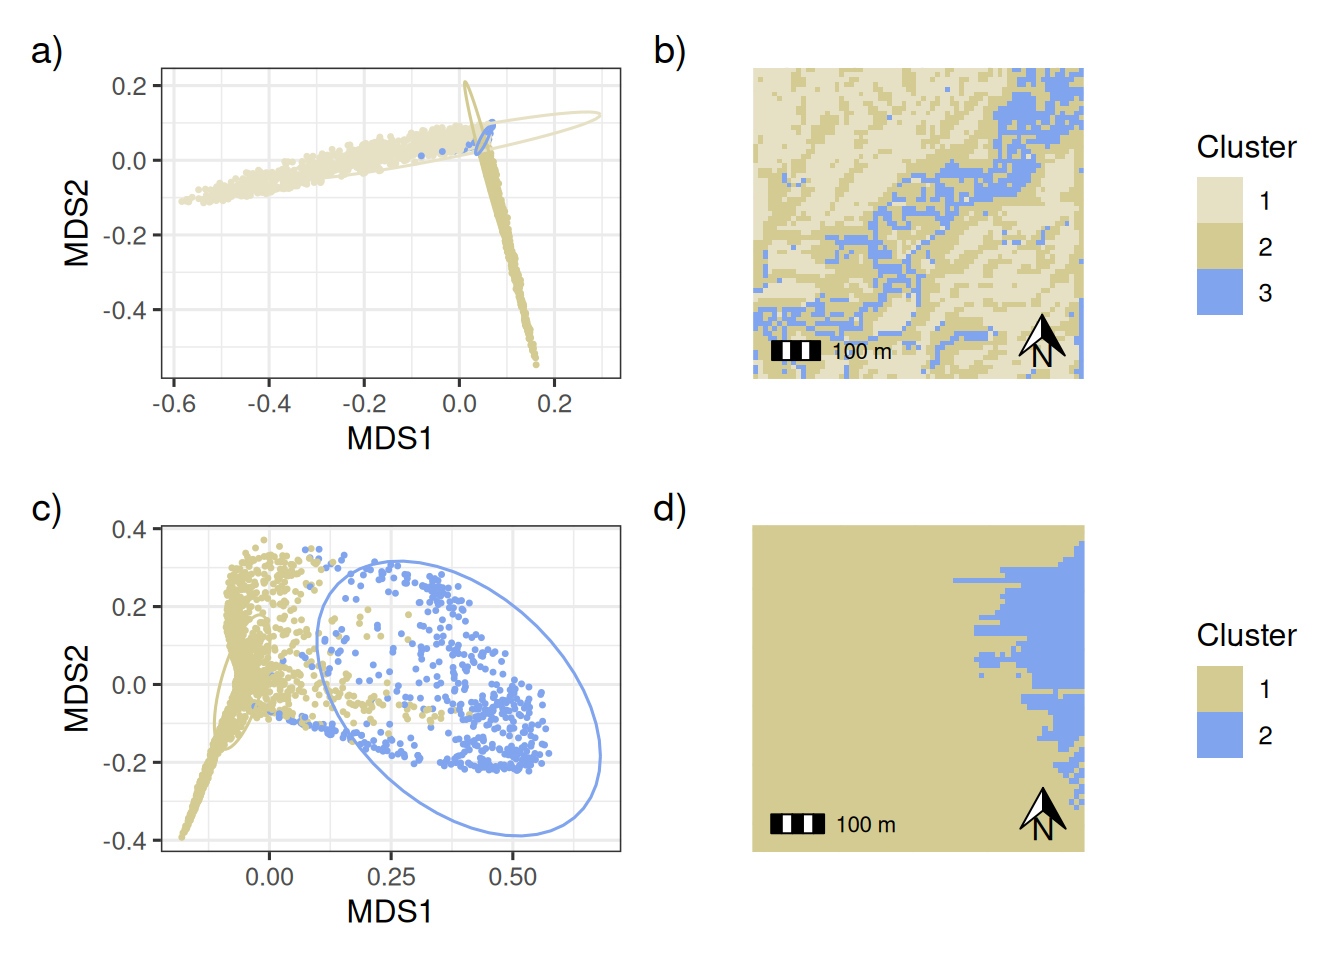

In [ ]:
#| label: fig-cluster
#| fig-cap: Maps and MDS plots demonstrating the clustering analysis of terrain attributes for the forest site (a, b) and the agricultural site (c, d).

cluster_plots <- forest_mds_plot + forest_cluster_map + ag_mds_plot + ag_cluster_map + plot_annotation(tag_levels = 'a', tag_suffix = ')') + plot_layout(heights = c(1, 1.05))
cluster_plots

# 
# (forest_cluster_map + ag_cluster_map)

#forest_cluster_map + ag_cluster_map + forest_pc + ag_pc + plot_annotation(tag_levels = 'a', tag_suffix = ')') + plot_layout(height = c(1, 1))

#ggsave(filename = "./Submission/Figure 4.png", plot = cluster_plots, height = 150, width = 200, units = "mm", dpi = 600)

In [ ]:
#| label: tbl-cluster-summary
#| tbl-cap: Summary of terrain attributes by land-use cluster. Each value is the cluster mean, with the standard deviation given in parentheses.

cluster_summary |>
  mutate(site = "Forest") |>
  bind_rows(ag_cluster_summary |>  mutate(site = "Agriculture"))|>
  mutate(attribute = as.character(fct_recode(attribute,  "Elevation" = "elevation", "Catchment Area" = "catchment_area", "Plan Curvature" = "plan_curvature", "Profile Curvature" = "profile_curvature", "Rel. Slope Position" = "relative_slope_position", "SAGA Wetness Index" = "saga_wetness_index", "Vert. Dist. Channel" = "channel_network_distance"))) |>
  mutate(attribute = factor(attribute, levels = c("Elevation", "SAGA Wetness Index", "Rel. Slope Position", "Vert. Dist. Channel", "Catchment Area", "Profile Curvature", "Plan Curvature"))) |>
  arrange(attribute) |> 
  rename(Attribute = attribute)|>
  group_by(site) |>
  gt() |>
  sub_missing(missing_text = "") |>
  tab_spanner(label = "Cluster",columns = c(2,3,4)) |>
  row_group_order(groups = c("Agriculture", "Forest")) |>
  tab_style(style =  cell_text(weight = "bold", align = "center"), locations =  cells_row_groups()) |>
  tab_style(style =  cell_text(weight = "bold", align = "left"), locations =  cells_column_labels()) |> 
  tab_style(style =  cell_text(align = "left"), locations =  cells_body())

Attribute 
 
 Cluster 
 
 
 
 1 
 2 
 3 
 
 
 
 
 Agriculture 
 
 Elevation 
 310.0 (0.6) 
 309.2 (0.1) 
 
 SAGA Wetness Index 
 9.5 (0.6) 
 10.6 (0.3) 
 
 Rel. Slope Position 
 0.8 (0.2) 
 0.2 (0.2) 
 
 Vert. Dist. Channel 
 0.1 (0.0) 
 0.0 (0.0) 
 
 Catchment Area 
 375.3 (728.4) 
 1183.9 (1983.2) 
 
 Profile Curvature 
 -0.0 (0.0) 
 -0.0 (0.0) 
 
 Plan Curvature 
 0.0 (0.0) 
 -0.0 (0.0) 
 
 
 Forest 
 
 Elevation 
 369.4 (2.5) 
 369.9 (3.3) 
 367.1 (4.4) 
 SAGA Wetness Index 
 6.7 (0.6) 
 5.5 (0.9) 
 5.2 (0.9) 
 Rel. Slope Position 
 0.1 (0.1) 
 0.4 (0.3) 
 0.1 (0.1) 
 Vert. Dist. Channel 
 0.1 (0.1) 
 0.7 (0.5) 
 0.5 (0.3) 
 Catchment Area 
 252.3 (425.3) 
 147.1 (520.5) 
 2571.6 (4255.4) 
 Profile Curvature 
 -0.0 (0.0) 
 0.0 (0.0) 
 -0.0 (0.0) 
 Plan Curvature 
 -0.0 (0.0) 
 0.0 (0.0) 
 0.0 (0.0)

In [ ]:
elbow_p <- k_plot_ag + k_plot_forest

#ggsave(filename = "./images/elbows.png", plot = elbow_p, height = 150, width = 200, units = "mm", dpi = 600)